# Shor's Factorization Algorithm with Qiskit

Shor's algorithm factors an integer **N** by reducing factoring to **order finding**: for a random `a` coprime to `N`, find the smallest `r` with

$$a^r \equiv 1 \pmod N$$

If `r` is even and $a^{r/2} \not\equiv -1 \pmod N$, then $\gcd(a^{r/2} \pm 1, N)$ gives non-trivial factors.

Finding `r` classically takes time exponential in the number of digits of N. A quantum computer finds it with **Quantum Phase Estimation (QPE)** + the **inverse Quantum Fourier Transform**.

This notebook factors **N = 247** in three parts:

1. **Classical baseline**: brute-force order finding
2. **Gate-level QPE for N = 15**: the textbook circuit built entirely from gates
3. **QPE for N = 247**: the same algorithm on the real target, using a matrix oracle for modular multiplication

In [1]:
import random
from fractions import Fraction
from math import gcd

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

N = 247
sim = AerSimulator()

---
## Part 1: Classical order finding

The slow part: multiply by `a` until we get back to 1. For an n-bit `N`, this can take up to ~N steps.

In [2]:
def find_order(a, N):
    """Smallest r > 0 with a^r = 1 (mod N), found by brute force."""
    r, val = 1, a % N
    while val != 1:
        val = (val * a) % N
        r += 1
    return r


def factors_from_order(a, r, N):
    """Turn an order r into factors of N, or None if this r is unusable."""
    if r % 2:
        return None
    x = pow(a, r // 2, N)
    if x == N - 1:
        return None
    for f in (gcd(x - 1, N), gcd(x + 1, N)):
        if 1 < f < N:
            return f, N // f
    return None


def shor_classical(N, seed=0):
    rng = random.Random(seed)
    while True:
        a = rng.randint(2, N - 1)
        if gcd(a, N) != 1:                 # lucky guess: a already shares a factor
            print(f"a = {a}: gcd(a, N) = {gcd(a, N)}, factor found directly")
            return gcd(a, N), N // gcd(a, N)
        r = find_order(a, N)
        result = factors_from_order(a, r, N)
        print(f"a = {a:3d}  ->  r = {r:2d}  ->  {'factors ' + str(result) if result else 'unusable, retry'}")
        if result:
            return result


p, q = shor_classical(N)
print(f"\n{N} = {p} x {q}")

a = 218  ->  r = 18  ->  factors (19, 13)

247 = 19 x 13


---
## Part 2: Gate-level QPE for N = 15

Fully gate-level modular multiplication for an arbitrary N needs a lot of qubits and gates, so the standard demonstration uses **N = 15**, where multiplying by `a mod 15` is just a pattern of SWAPs and X gates on 4 qubits.

**Circuit:**
1. Counting register in uniform superposition (Hadamards)
2. Work register initialized to |1⟩
3. Counting qubit *k* controls $U^{2^k}$, where $U|y⟩ = |a\,y \bmod N⟩$
4. Inverse QFT on the counting register
5. Measure → a value close to $2^n \cdot s/r$; continued fractions recover `r`

### Quantum Fourier Transform

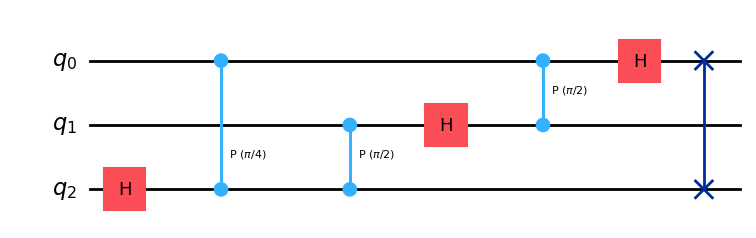

In [3]:
def qft(n):
    """n-qubit Quantum Fourier Transform."""
    qc = QuantumCircuit(n, name="QFT")
    for j in reversed(range(n)):
        qc.h(j)
        for k in range(j):
            qc.cp(np.pi / 2 ** (j - k), k, j)
    for i in range(n // 2):
        qc.swap(i, n - i - 1)
    return qc


def iqft(n):
    g = qft(n).inverse()
    g.name = "QFT†"
    return g


qft(3).draw("mpl")

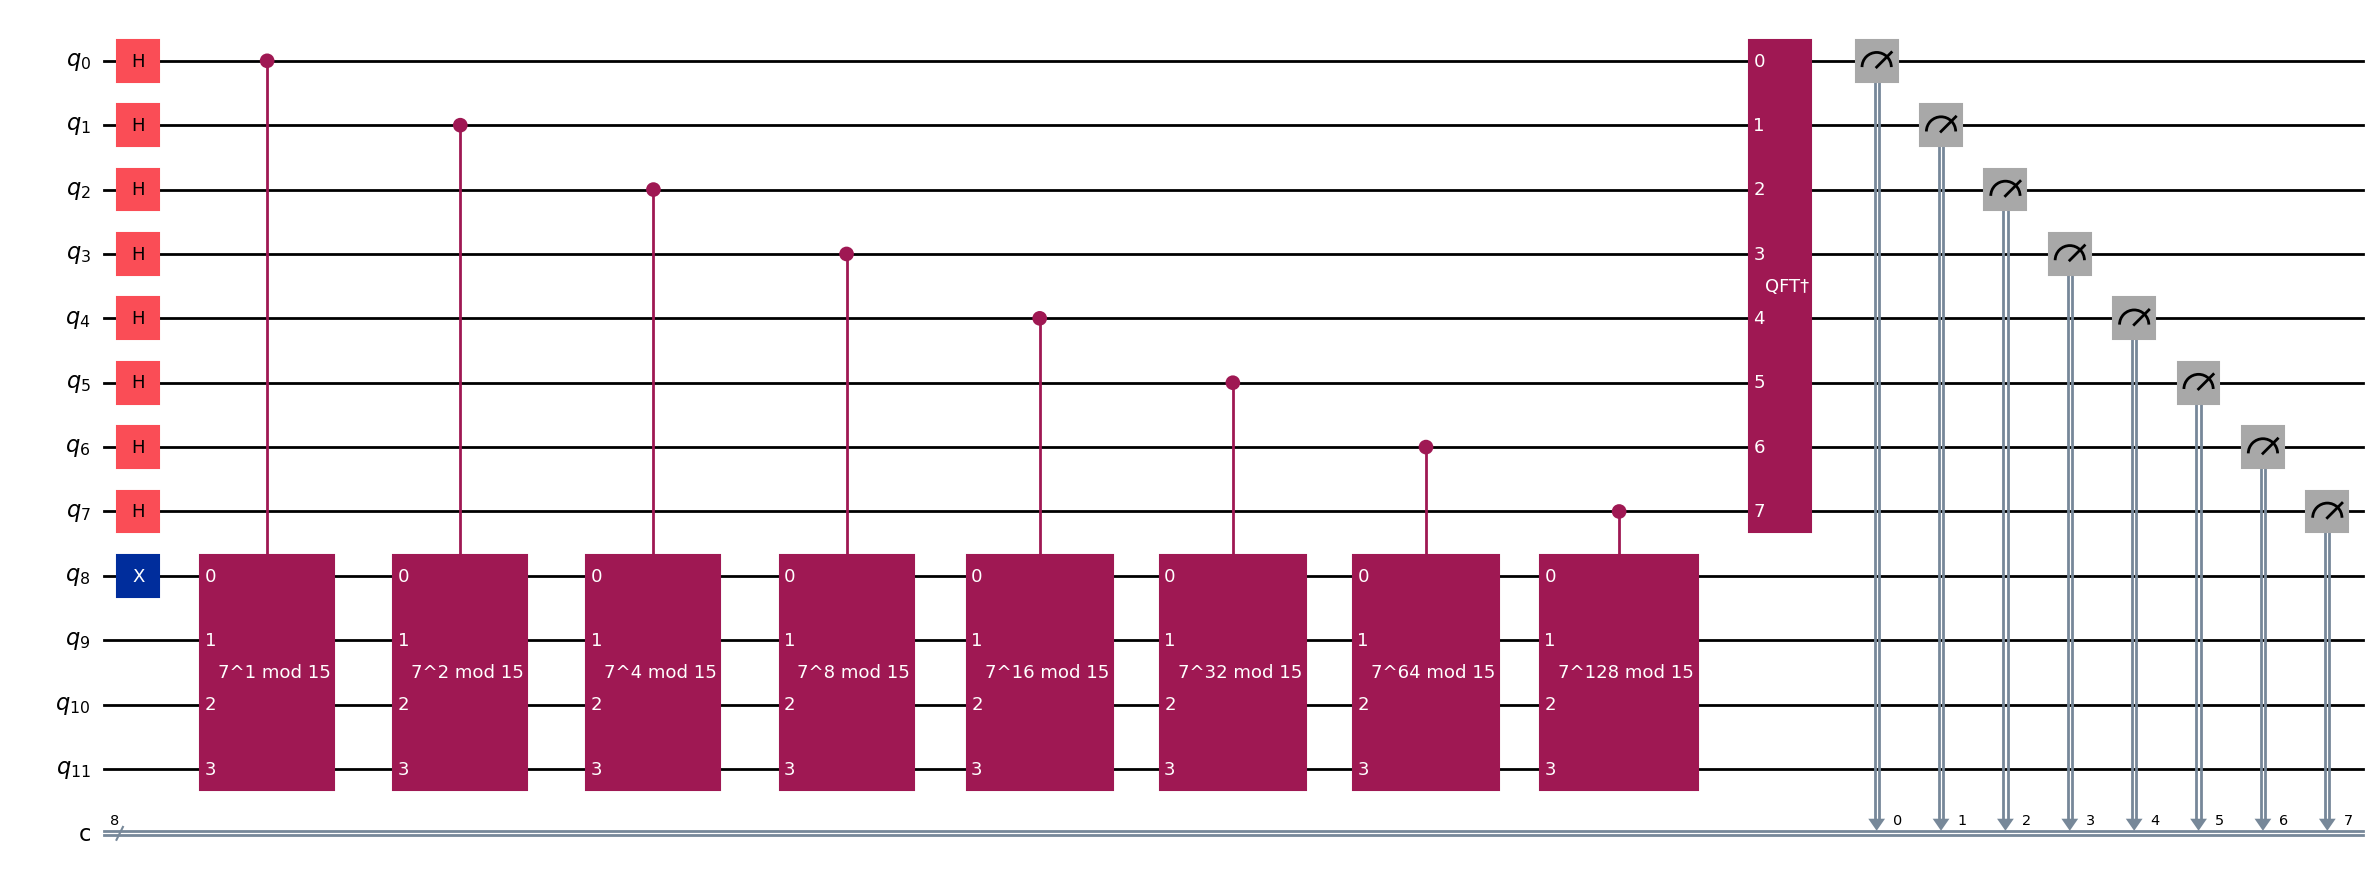

In [4]:
def c_amod15(a, power):
    """Controlled U^power where U|y> = |a*y mod 15>."""
    U = QuantumCircuit(4)
    for _ in range(power % 4):           # every valid a has order dividing 4
        if a in (2, 13):
            U.swap(2, 3); U.swap(1, 2); U.swap(0, 1)
        if a in (7, 8):
            U.swap(0, 1); U.swap(1, 2); U.swap(2, 3)
        if a in (4, 11):
            U.swap(1, 3); U.swap(0, 2)
        if a in (7, 11, 13):
            U.x(range(4))
    gate = U.to_gate(label=f"{a}^{power} mod 15")
    return gate.control()


def qpe_mod15(a, n_count=8):
    qc = QuantumCircuit(n_count + 4, n_count)
    qc.h(range(n_count))
    qc.x(n_count)                                     # work register = |1>
    for k in range(n_count):
        qc.append(c_amod15(a, 2 ** k), [k] + list(range(n_count, n_count + 4)))
    qc.append(iqft(n_count), range(n_count))
    qc.measure(range(n_count), range(n_count))
    return qc


qc15 = qpe_mod15(7)
qc15.draw("mpl", fold=-1)

  measured  count    phase     s/r
  01000000    526   0.2500     1/4
  11000000    514   0.7500     3/4
  00000000    507   0.0000       0
  10000000    501   0.5000     1/2


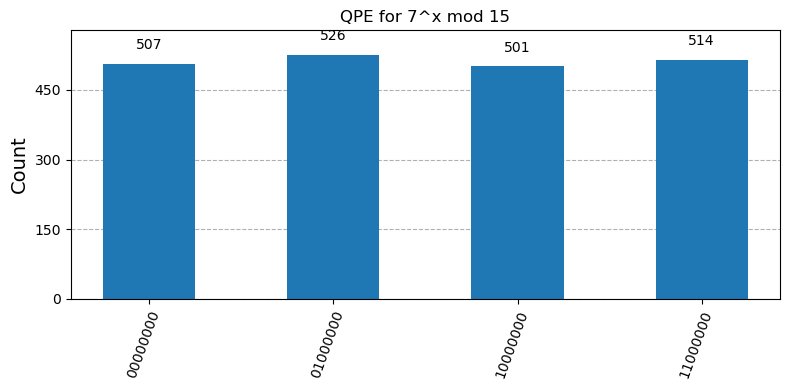

In [5]:
def order_candidates(counts, n_count, N):
    """Measured phase s/r -> continued fractions -> candidate r, ranked by counts."""
    rows = []
    for bits, cnt in sorted(counts.items(), key=lambda x: -x[1]):
        phase = int(bits, 2) / 2 ** n_count
        frac = Fraction(phase).limit_denominator(N)
        rows.append((bits, cnt, phase, frac))
    return rows


counts15 = sim.run(transpile(qc15, sim), shots=2048).result().get_counts()
print(f"{'measured':>10}  {'count':>5}  {'phase':>7}  {'s/r':>6}")
for bits, cnt, phase, frac in order_candidates(counts15, 8, 15):
    print(f"{bits:>10}  {cnt:5d}  {phase:7.4f}  {str(frac):>6}")

plot_histogram(counts15, title="QPE for 7^x mod 15", figsize=(8, 4))

Peaks at phases 0, 1/4, 1/2, 3/4 → **r = 4**. Then $7^2 \bmod 15 = 4$, and $\gcd(3, 15) = 3$, $\gcd(5, 15) = 5$.

In [6]:
r15 = max(frac.denominator for *_, frac in order_candidates(counts15, 8, 15))
print(f"r = {r15}  ->  15 = {factors_from_order(7, r15, 15)}")

r = 4  ->  15 = (3, 5)


---
## Part 3: QPE for N = 247

Same algorithm, now on the real target. N = 247 needs **8 work qubits** (2⁸ = 256 ≥ 247). Instead of synthesizing a reversible modular multiplier out of gates, each controlled-$U^{2^k}$ is supplied as a **permutation-matrix oracle** (`UnitaryGate`). The Aer simulator applies it directly.

> This is a simulation shortcut: the matrix isn't a gate-efficient circuit, but the quantum part (superposition → phase kickback → inverse QFT → measurement) is exactly Shor's algorithm.

We use **a = 7** and **10 counting qubits** (18 qubits total).

In [7]:
N_WORK = 8      # 2^8 = 256 >= 247
N_COUNT = 10
a = 7
assert gcd(a, N) == 1


def c_mult_mod(mult, N, n_work=N_WORK):
    """Controlled |y> -> |mult*y mod N> as a permutation matrix (control = qubit 0)."""
    dim = 2 ** (n_work + 1)
    M = np.zeros((dim, dim))
    for i in range(dim):
        ctrl, y = i & 1, i >> 1
        y_out = (y * mult) % N if (ctrl and y < N) else y   # states >= N are left alone
        M[(y_out << 1) | ctrl, i] = 1
    return UnitaryGate(M, label=f"x{mult} mod {N}")


def qpe_modN(a, N, n_count=N_COUNT, n_work=N_WORK):
    qc = QuantumCircuit(n_count + n_work, n_count)
    qc.h(range(n_count))
    qc.x(n_count)
    work = list(range(n_count, n_count + n_work))
    for k in range(n_count):
        qc.append(c_mult_mod(pow(a, 2 ** k, N), N, n_work), [k] + work)
    qc.append(iqft(n_count), range(n_count))
    qc.measure(range(n_count), range(n_count))
    return qc


qc247 = qpe_modN(a, N)
print(f"qubits: {qc247.num_qubits}  ({N_COUNT} counting + {N_WORK} work)")
counts247 = sim.run(transpile(qc247, sim), shots=4096).result().get_counts()

print(f"\n{'measured':>12}  {'count':>5}  {'phase':>7}  {'s/r':>6}")
for bits, cnt, phase, frac in order_candidates(counts247, N_COUNT, N)[:12]:
    print(f"{bits:>12}  {cnt:5d}  {phase:7.4f}  {str(frac):>6}")

qubits: 18  (10 counting + 8 work)



    measured  count    phase     s/r
  0000000000    368   0.0000       0
  1100000000    328   0.7500     3/4
  1000000000    324   0.5000     1/2
  0100000000    313   0.2500     1/4
  0101010101    274   0.3330     1/3
  0010101011    262   0.1670     1/6
  0001010101    261   0.0830  20/241
  1001010101    259   0.5830  144/247
  1110101011    225   0.9170  221/241
  1010101011    225   0.6670     2/3
  0110101011    219   0.4170  103/247
  1101010101    214   0.8330     5/6


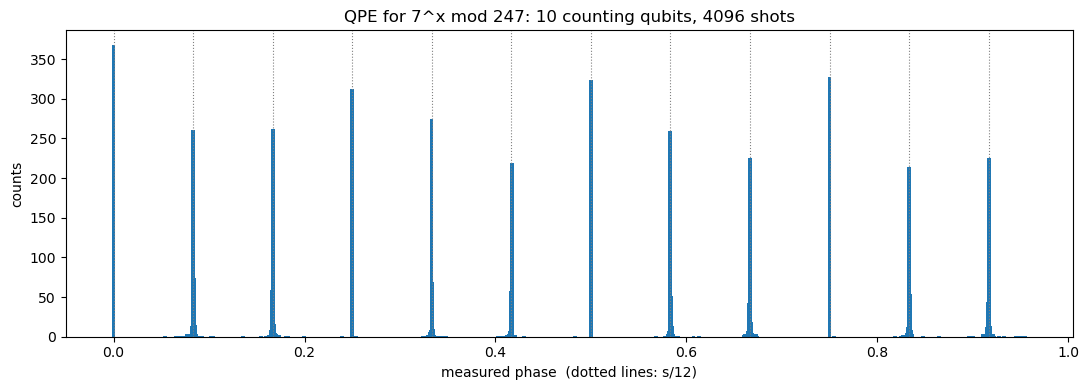

In [8]:
# Histogram of the measured phase
phases = {int(b, 2) / 2 ** N_COUNT: c for b, c in counts247.items()}
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(list(phases), list(phases.values()), width=0.004)
for s in range(12):
    ax.axvline(s / 12, color="gray", ls=":", lw=0.8)
ax.set_xlabel("measured phase  (dotted lines: s/12)")
ax.set_ylabel("counts")
ax.set_title(f"QPE for {a}^x mod {N}: {N_COUNT} counting qubits, 4096 shots")
plt.tight_layout()
plt.savefig("../images/shor_qpe_247.png", dpi=130)
plt.show()

The peaks sit at multiples of 1/12. A single measurement only gives $s/r$ in lowest terms (e.g. 1/4 or 1/3), and since 2¹⁰ isn't a multiple of 12 some peaks are slightly off (e.g. 20/241). So we take the denominators of the most frequent outcomes, combine pairs with **LCM**, and keep the smallest candidate that actually satisfies $a^r \equiv 1 \pmod N$.

In [9]:
from itertools import combinations_with_replacement
from math import lcm

top = order_candidates(counts247, N_COUNT, N)[:8]
denoms = {frac.denominator for *_, frac in top if frac.numerator}
print(f"denominators from top outcomes: {sorted(denoms)}")

r = min(lcm(d1, d2) for d1, d2 in combinations_with_replacement(denoms, 2)
        if pow(a, lcm(d1, d2), N) == 1)

print(f"recovered r = {r}")
print(f"check: {a}^{r} mod {N} = {pow(a, r, N)}")
print(f"classical brute force says r = {find_order(a, N)}")

result = factors_from_order(a, r, N)
x = pow(a, r // 2, N)
print(f"\n{a}^(r/2) mod {N} = {x}")
print(f"gcd({x} - 1, {N}) = {gcd(x - 1, N)},  gcd({x} + 1, {N}) = {gcd(x + 1, N)}")
print(f"\n{N} = {result[0]} x {result[1]}")

denominators from top outcomes: [2, 3, 4, 6, 241, 247]
recovered r = 12
check: 7^12 mod 247 = 1
classical brute force says r = 12

7^(r/2) mod 247 = 77
gcd(77 - 1, 247) = 19,  gcd(77 + 1, 247) = 13

247 = 19 x 13


---
## Summary

| Part | Method | N | a | r | Factors |
|------|--------|---|---|---|---------|
| 1 | Classical brute-force order finding | 247 | random | — | 13 × 19 |
| 2 | Gate-level QPE (SWAP/X modular multiplier) | 15 | 7 | 4 | 3 × 5 |
| 3 | QPE with matrix oracle, 18 qubits | 247 | 7 | 12 | 13 × 19 |

**Why it's fast:** the counting register holds every exponent x at once, phase kickback writes $a^x \bmod N$'s periodicity into the phases, and the inverse QFT turns that periodicity into sharp peaks at $s/r$. Wrong frequencies cancel out by destructive interference.